# 01. Análise exploratória da base de clientes

**Objetivo:** entender quem são os clientes que atrasam mais de 15 dias no período de previsão e quais informações do histórico ajudam a identificá-los antes do atraso.

**Base:** `analytics.client_base`, criada em `sql/05_analytics_client_base.sql`. Uma linha por cliente, com o comportamento de pagamento até a data de corte, o cadastro e o resultado no período de previsão.

## 1. Preparação

Importa as bibliotecas, localiza a pasta do projeto e libera as funções da pasta `src/`, que ficam fora do notebook para poderem ser reaproveitadas.

In [10]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Pasta raiz do projeto: a primeira pasta acima que tem o environment.yml
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "environment.yml").exists())
sys.path.append(str(ROOT / "src"))

from db import get_engine
from eda import plot_risk, risk_by_group

FIG_DIR = ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

## 2. Leitura dos dados

Lê a tabela inteira do SQL Server. O banco devolve as colunas decimais num formato que o pandas trata como texto, então elas são convertidas para número.

In [11]:
df = pd.read_sql("SELECT * FROM analytics.client_base", get_engine())

text_cols = ["income_type", "education_level"]
num_cols = df.columns.difference(text_cols)
df[num_cols] = df[num_cols].astype(float)
df["client_id"] = df["client_id"].astype(int)

print(f"{len(df):,} clientes e {df.shape[1]} colunas")
df.head()

156,333 clientes e 24 colunas


,client_id,hist_contracts,hist_installments,hist_amount_due,hist_pct_late,hist_pct_late_15,hist_max_days_late,hist_avg_days_late,hist_pct_split_payment,recent_installments,...,age_years,years_employed,no_current_job,income_type,education_level,region_rating,window_installments,window_amount_due,target_late_15,target_late_30
0,100002,1.00,7.00,"64,762.43",0.00,0.00,-22.00,-25.29,0.00,6.00,...,25.00,1.70,0.00,Working,Secondary / secondary special,2.00,12.00,"154,863.27",0.00,0.00
1,100007,4.00,50.00,"597,630.20",0.32,0.00,12.00,-2.04,0.06,6.00,...,54.00,8.30,0.00,Working,Secondary / secondary special,2.00,12.00,"192,460.14",0.00,0.00
2,100008,3.00,24.00,"778,768.97",0.04,0.04,"1,317.00",43.79,0.04,5.00,...,46.00,4.30,0.00,State servant,Secondary / secondary special,2.00,10.00,"178,848.63",0.00,0.00
3,100009,4.00,24.00,"265,058.24",0.00,0.00,-1.00,-7.67,0.00,2.00,...,37.00,8.60,0.00,Commercial associate,Higher education,2.00,10.00,"89,962.38",0.00,0.00
4,100011,2.00,39.00,"1,020,317.99",0.41,0.03,958.00,23.82,0.23,6.00,...,55.00,NaN,1.00,Pensioner,Secondary / secondary special,2.00,3.00,"93,488.09",0.00,0.00


## 3. Campos vazios

Mostra o percentual de clientes sem informação em cada coluna. Vazios esperados: o cadastro dos clientes sem `has_profile`, o tempo de emprego de quem não tem emprego atual e os indicadores recentes de quem não teve parcelas nos 6 meses antes do corte.

In [12]:
nulls = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
nulls[nulls > 0].to_frame("% vazio")

,% vazio
years_employed,31.30
income,14.20
region_rating,14.20
education_level,14.20
income_type,14.20
no_current_job,14.20
age_years,14.20
recent_pct_late,3.50
recent_max_days_late,3.50


## 4. O alvo

Quantos clientes atrasaram mais de 15 dias (alvo principal) e mais de 30 dias (alvo da análise de sensibilidade) no período de previsão.

In [13]:
base_rate = df["target_late_15"].mean() * 100

pd.DataFrame(
    {
        "clientes em risco": [df["target_late_15"].sum(), df["target_late_30"].sum()],
        "taxa (%)": [base_rate, df["target_late_30"].mean() * 100],
    },
    index=["atraso acima de 15 dias", "atraso acima de 30 dias"],
)

,clientes em risco,taxa (%)
atraso acima de 15 dias,"2,621.00",1.68
atraso acima de 30 dias,"1,095.00",0.70


## 5. Valor em jogo

Quanto há a receber no período de previsão e quanto disso está com os clientes que vieram a atrasar mais de 15 dias. É o primeiro indicador de caixa do projeto.

In [14]:
total_due = df["window_amount_due"].sum()
risk_due = df.loc[df["target_late_15"] == 1, "window_amount_due"].sum()

print(f"Valor a receber no período: {total_due:,.0f}")
print(f"Com clientes que atrasaram mais de 15 dias: {risk_due:,.0f} ({risk_due / total_due:.1%})")

Valor a receber no período: 41,581,930,848
Com clientes que atrasaram mais de 15 dias: 722,528,594 (1.7%)


## 6. O histórico de pagamento explica o risco?

Divide os clientes em faixas de três indicadores do histórico e compara a taxa de risco de cada faixa com a média da base. Se as faixas piores tiverem taxas bem acima da média, o histórico é um bom sinal para o modelo.

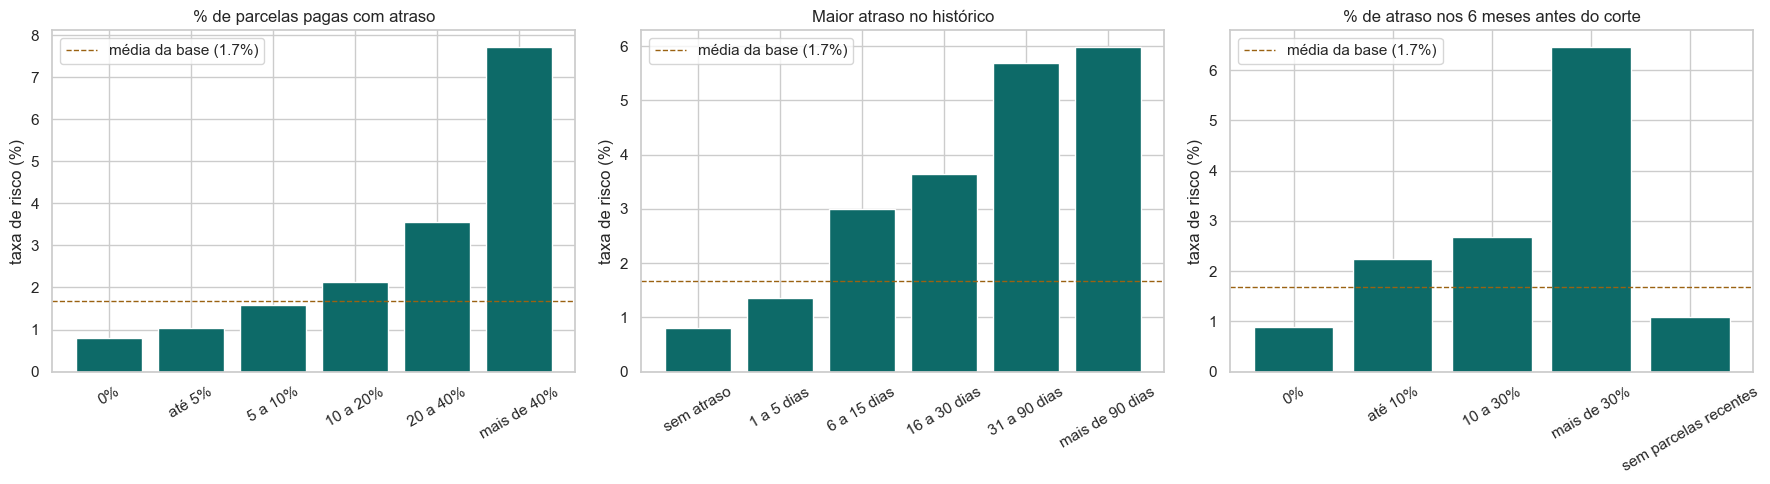

% de parcelas pagas com atraso


,clientes,pct_base,em_risco,taxa_risco
faixa_pct_atraso,,,,
0%,83327,53.30,666.00,0.80
até 5%,14390,9.20,148.00,1.03
5 a 10%,16017,10.25,252.00,1.57
10 a 20%,19046,12.18,406.00,2.13
20 a 40%,16121,10.31,575.00,3.57
mais de 40%,7432,4.75,574.00,7.72


Maior atraso no histórico


,clientes,pct_base,em_risco,taxa_risco
faixa_maior_atraso,,,,
sem atraso,83327,53.30,666.00,0.80
1 a 5 dias,31553,20.18,427.00,1.35
6 a 15 dias,22112,14.14,663.00,3.00
16 a 30 dias,11925,7.63,435.00,3.65
31 a 90 dias,4594,2.94,261.00,5.68
mais de 90 dias,2822,1.81,169.00,5.99


% de atraso nos 6 meses antes do corte


,clientes,pct_base,em_risco,taxa_risco
faixa_atraso_recente,,,,
0%,116572,74.57,"1,037.00",0.89
até 10%,2686,1.72,60.00,2.23
10 a 30%,15347,9.82,410.00,2.67
mais de 30%,16307,10.43,"1,055.00",6.47
sem parcelas recentes,5421,3.47,59.00,1.09


In [15]:
df["faixa_pct_atraso"] = pd.cut(
    df["hist_pct_late"],
    bins=[-0.01, 0, 0.05, 0.10, 0.20, 0.40, 1.0],
    labels=["0%", "até 5%", "5 a 10%", "10 a 20%", "20 a 40%", "mais de 40%"],
)
df["faixa_maior_atraso"] = pd.cut(
    df["hist_max_days_late"],
    bins=[-np.inf, 0, 5, 15, 30, 90, np.inf],
    labels=["sem atraso", "1 a 5 dias", "6 a 15 dias", "16 a 30 dias", "31 a 90 dias", "mais de 90 dias"],
)
df["faixa_atraso_recente"] = (
    pd.cut(df["recent_pct_late"], bins=[-0.01, 0, 0.10, 0.30, 1.0],
           labels=["0%", "até 10%", "10 a 30%", "mais de 30%"])
    .cat.add_categories("sem parcelas recentes")
    .fillna("sem parcelas recentes")
)

hist_tables = {
    "% de parcelas pagas com atraso": risk_by_group(df, "faixa_pct_atraso"),
    "Maior atraso no histórico": risk_by_group(df, "faixa_maior_atraso"),
    "% de atraso nos 6 meses antes do corte": risk_by_group(df, "faixa_atraso_recente"),
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (title, table) in zip(axes, hist_tables.items()):
    plot_risk(table, title, base_rate, ax)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_risco_por_historico.png", dpi=150)
plt.show()

for title, table in hist_tables.items():
    print(title)
    display(table)

## 7. O perfil do cliente explica o risco?

Mesma comparação com os dados cadastrais, só para os clientes que têm cadastro. Renda em quintis: cada faixa tem 20% dos clientes.

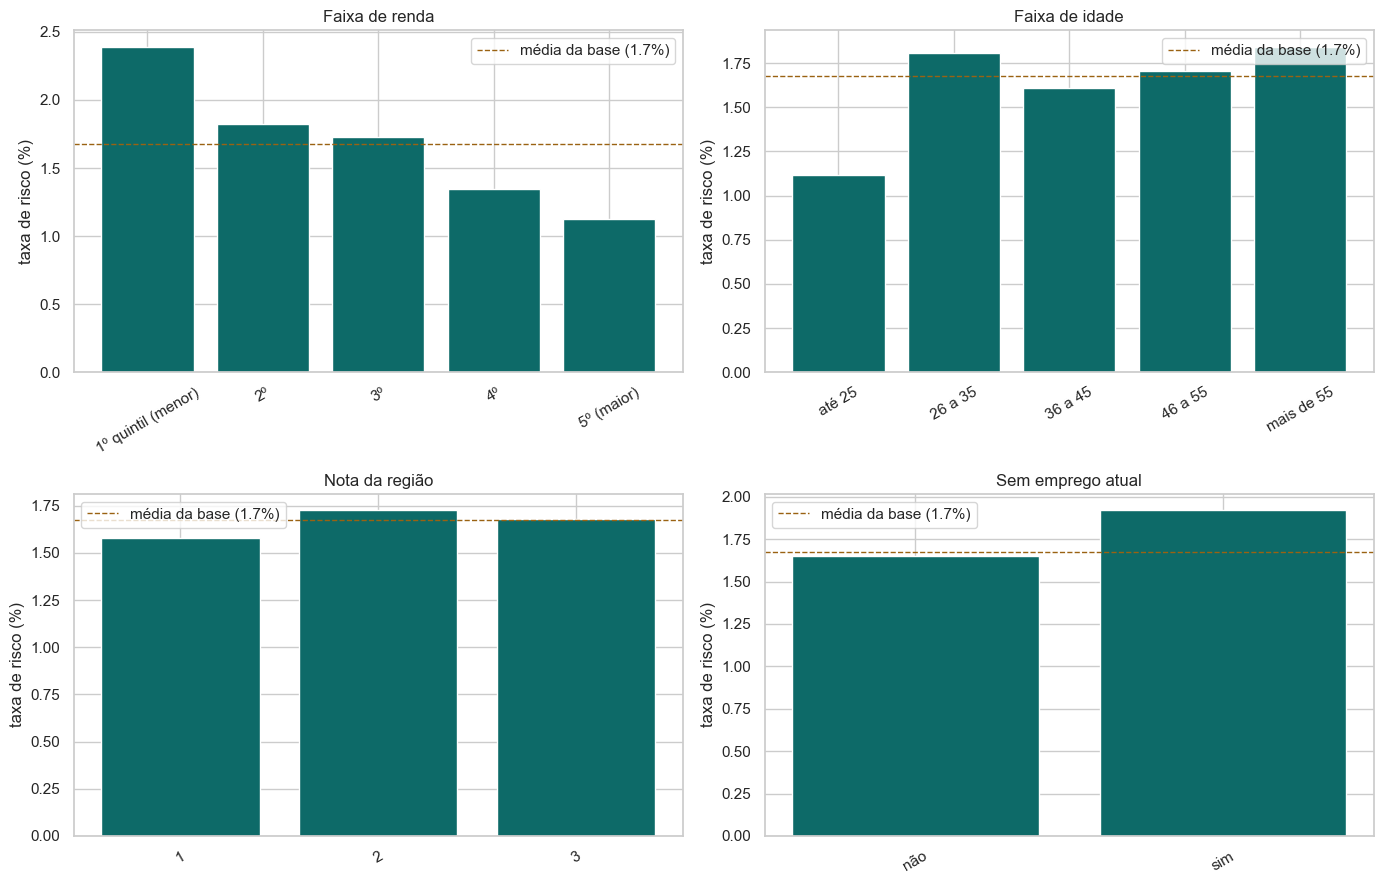

Faixa de renda


,clientes,pct_base,em_risco,taxa_risco
faixa_renda,,,,
1º quintil (menor),27591,20.57,660.00,2.39
2º,35813,26.71,652.00,1.82
3º,18032,13.45,311.00,1.72
4º,31785,23.70,427.00,1.34
5º (maior),20884,15.57,235.00,1.13


Faixa de idade


,clientes,pct_base,em_risco,taxa_risco
faixa_idade,,,,
até 25,6996,5.22,78.00,1.11
26 a 35,30509,22.75,552.00,1.81
36 a 45,35526,26.49,572.00,1.61
46 a 55,30685,22.88,523.00,1.70
mais de 55,30389,22.66,560.00,1.84


Nota da região


,clientes,pct_base,em_risco,taxa_risco
region_rating,,,,
1,13228,9.86,209.00,1.58
2,98326,73.32,"1,697.00",1.73
3,22551,16.82,379.00,1.68


... (2 outputs left out)

Tipo de renda


,clientes,pct_base,em_risco,taxa_risco
income_type,,,,
Commercial associate,29696,22.14,447.00,1.51
Maternity leave,1,0.00,1.00,100.00
Pensioner,26652,19.87,501.00,1.88
State servant,8940,6.67,136.00,1.52
Student,3,0.00,0.00,0.00
Unemployed,15,0.01,11.00,73.33
Working,68798,51.30,"1,189.00",1.73


Escolaridade


,clientes,pct_base,em_risco,taxa_risco
education_level,,,,
Academic degree,60,0.04,2.00,3.33
Higher education,29355,21.89,400.00,1.36
Incomplete higher,4269,3.18,76.00,1.78
Lower secondary,1719,1.28,37.00,2.15
Secondary / secondary special,98702,73.60,"1,770.00",1.79


In [16]:
prof = df[df["has_profile"] == 1].copy()
prof["faixa_renda"] = pd.qcut(prof["income"], 5, labels=["1º quintil (menor)", "2º", "3º", "4º", "5º (maior)"])
prof["region_rating"] = prof["region_rating"].astype(int)
prof["no_current_job"] = prof["no_current_job"].map({0: "não", 1: "sim"})
prof["faixa_idade"] = pd.cut(prof["age_years"], bins=[0, 25, 35, 45, 55, 120],
                             labels=["até 25", "26 a 35", "36 a 45", "46 a 55", "mais de 55"])

profile_tables = {
    "Faixa de renda": risk_by_group(prof, "faixa_renda"),
    "Faixa de idade": risk_by_group(prof, "faixa_idade"),
    "Nota da região": risk_by_group(prof, "region_rating"),
    "Sem emprego atual": risk_by_group(prof, "no_current_job"),
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (title, table) in zip(axes.flat, profile_tables.items()):
    plot_risk(table, title, base_rate, ax)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_risco_por_perfil.png", dpi=150)
plt.show()

for title, table in profile_tables.items():
    print(title)
    display(table)

print("Tipo de renda")
display(risk_by_group(prof, "income_type"))
print("Escolaridade")
display(risk_by_group(prof, "education_level"))

## 8. Clientes com e sem cadastro

Verifica se os clientes sem cadastro (vindos do arquivo de teste do Kaggle) têm comportamento diferente. Isso orienta como tratá-los no modelo.

In [17]:
risk_by_group(df.assign(has_profile=df["has_profile"].map({0: "não", 1: "sim"})), "has_profile")


,clientes,pct_base,em_risco,taxa_risco
has_profile,,,,
não,22228,14.22,336.00,1.51
sim,134105,85.78,"2,285.00",1.70


## 9. Resumo para a próxima etapa

Taxa de risco por faixa dos dois indicadores de histórico mais relevantes e a comparação entre clientes com e sem cadastro.

In [18]:
print(f"Clientes: {len(df):,} | taxa de risco: {base_rate:.2f}% | valor em risco: {risk_due / total_due:.1%}\n")
for name, col in [("Maior atraso no histórico", "faixa_maior_atraso"),
                  ("Atraso nos 6 meses antes do corte", "faixa_atraso_recente"),
                  ("Tem cadastro", "has_profile")]:
    print(name)
    print(risk_by_group(df, col)[["clientes", "taxa_risco"]].round(2).to_string(), "\n")

Clientes: 156,333 | taxa de risco: 1.68% | valor em risco: 1.7%

Maior atraso no histórico
                    clientes  taxa_risco
faixa_maior_atraso                      
sem atraso             83327        0.80
1 a 5 dias             31553        1.35
6 a 15 dias            22112        3.00
16 a 30 dias           11925        3.65
31 a 90 dias            4594        5.68
mais de 90 dias         2822        5.99 

Atraso nos 6 meses antes do corte
                       clientes  taxa_risco
faixa_atraso_recente                       
0%                       116572        0.89
até 10%                    2686        2.23
10 a 30%                  15347        2.67
mais de 30%               16307        6.47
sem parcelas recentes      5421        1.09 

Tem cadastro
             clientes  taxa_risco
has_profile                      
0.00            22228        1.51
1.00           134105        1.70 



## 10. Conclusões

**Tamanho do problema.** São 156.333 clientes, e 2.621 (1,68%) atrasaram mais de 15 dias no período de previsão. Eles respondem por 1,7% do valor a receber no período. A base é desbalanceada, como é comum em cobrança.

**O histórico de pagamento é o sinal mais forte.** A taxa de risco sobe de forma consistente conforme piora o histórico:
- clientes que nunca atrasaram (53% da base) têm 0,8% de risco; os que pagaram mais de 40% das parcelas com atraso têm 7,7%, cerca de 4,6 vezes a média;
- quem já teve atraso acima de 30 dias tem cerca de 6% de risco;
- o atraso recente é o indicador mais útil para a cobrança: os clientes com mais de 30% das parcelas atrasadas nos 6 meses antes do corte são 10% da base e concentram 40% dos casos de risco (1.055 de 2.621).

**O perfil cadastral ajuda pouco.** Só a renda mostra um efeito claro (2,4% de risco no quintil de menor renda contra 1,1% no de maior renda). Idade, nota da região e emprego ficam próximos da média. Como o cadastro é do pedido atual, posterior ao corte, depender pouco dele também reduz o risco de vazamento.

**Decisões para o modelo:**
- usar todos os clientes, inclusive os sem cadastro (taxa de 1,5%, próxima da dos demais, 1,7%), com o indicador `has_profile` e tratamento dos campos vazios;
- agrupar tipos de renda muito raros (desempregado, licença-maternidade e estudante, 19 clientes no total) numa categoria "outros", porque percentuais calculados sobre poucos clientes não são confiáveis;
- dar prioridade aos indicadores de comportamento, especialmente os recentes.
